
# COU 07506 Digital Signal Processing — Week 3: Convolution, Correlation and Difference Equations

**Name:** Victoria Bintu Birhanenwa

**Registration No.:** 25024592742

**Class:** BENG24COE


**Date:** 22 November 2026


Task 3.1 — Convolution from the definition

In [3]:
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)

    for n in range(N):
        for k in range(len(x)):
            if 0 <= n-k < len(h):
                y[n] += x[k] * h[n-k]

    return y

In [5]:
import numpy as np

In [6]:
print(conv([1, 2, 3, 1], [1, 1, 1]))

[1. 3. 6. 6. 4. 1.]


In [7]:
print(np.convolve([1, 2, 3, 1], [1, 1, 1]))

[1 3 6 6 4 1]


In [8]:
x = [1, -1, 2]
h = [2, 1, 0, 1]

print(conv(x, h))

[ 2. -1.  3.  3. -1.  2.]


In [9]:
import time

x = np.random.rand(2000)
h = np.random.rand(2000)

start = time.perf_counter()
conv(x, h)
end = time.perf_counter()

print("Our convolution time:", end - start, "seconds")

start = time.perf_counter()
np.convolve(x, h)
end = time.perf_counter()

print("NumPy convolution time:", end - start, "seconds")

Our convolution time: 2.8166036150000764 seconds
NumPy convolution time: 0.0019824319999770523 seconds


**Observation:**

The manually implemented convolution function took approximately 2.8166 seconds, while NumPy's built-in `np.convolve()` took approximately 0.00198 seconds. This shows that NumPy is significantly faster because it uses optimized numerical operations compared to ordinary Python loops. Both methods produced the same mathematical result.

Task 3.2 — Smoothing a noisy signal by convolution

In [10]:

# Generate a noisy signal

n = np.arange(300)

w = np.random.randn(300)

x = np.sin(2 * np.pi * n / 50) + 0.5 * w


In [12]:
import matplotlib.pyplot as plt

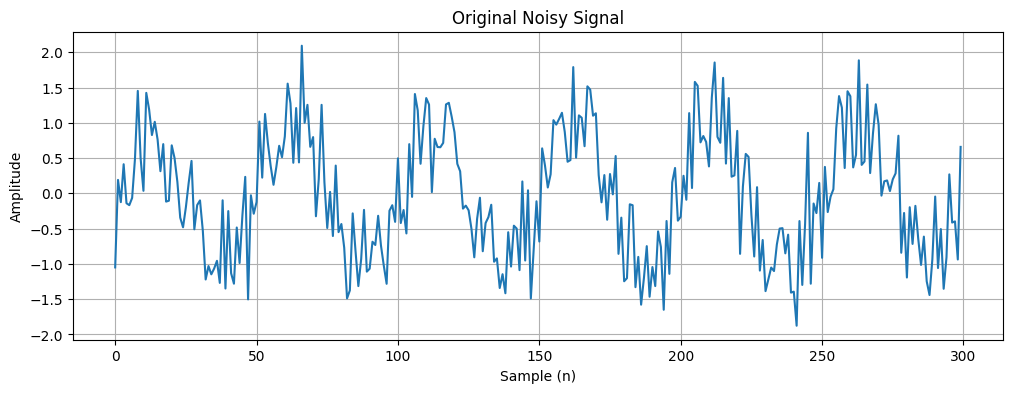

In [13]:
plt.figure(figsize=(12, 4))

plt.plot(n, x)

plt.title("Original Noisy Signal")
plt.xlabel("Sample (n)")
plt.ylabel("Amplitude")

plt.grid()
plt.show()

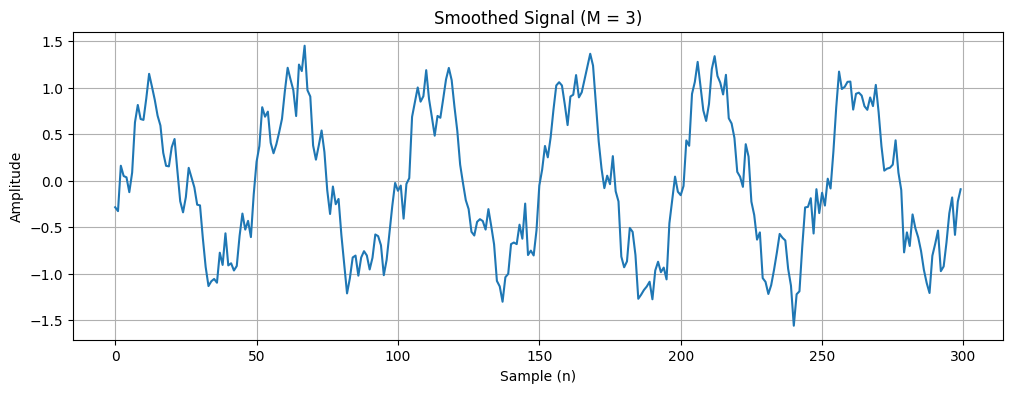

In [14]:
M = 3

h = np.ones(M) / M

y3 = np.convolve(x, h, mode="same")

plt.figure(figsize=(12, 4))
plt.plot(n, y3)
plt.title("Smoothed Signal (M = 3)")
plt.xlabel("Sample (n)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

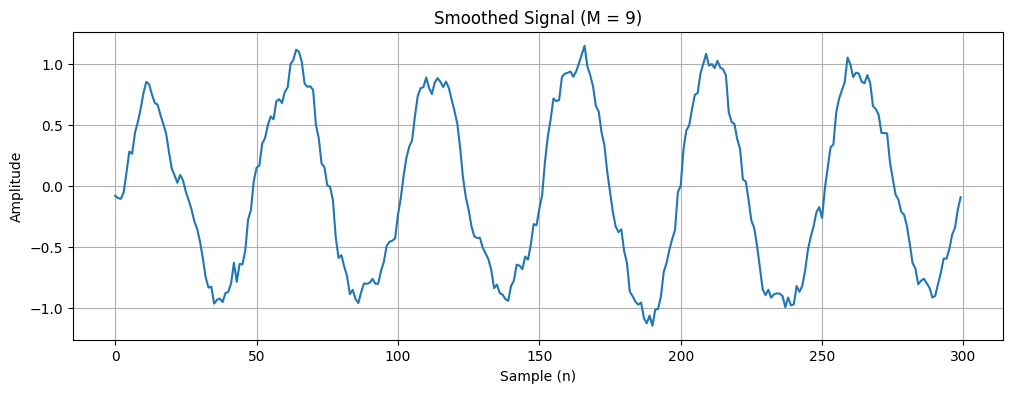

In [15]:
M = 9

h = np.ones(M) / M

y9 = np.convolve(x, h, mode="same")

plt.figure(figsize=(12, 4))
plt.plot(n, y9)
plt.title("Smoothed Signal (M = 9)")
plt.xlabel("Sample (n)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

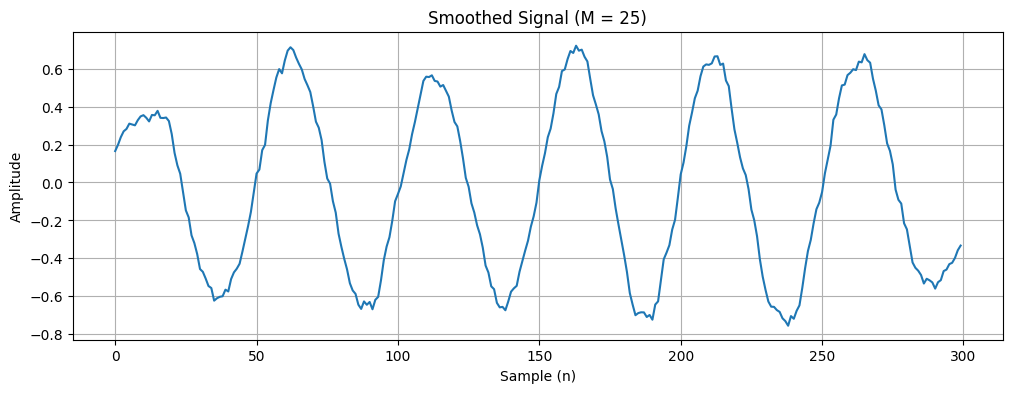

In [16]:
M = 25

h = np.ones(M) / M

y25 = np.convolve(x, h, mode="same")

plt.figure(figsize=(12, 4))
plt.plot(n, y25)
plt.title("Smoothed Signal (M = 25)")
plt.xlabel("Sample (n)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

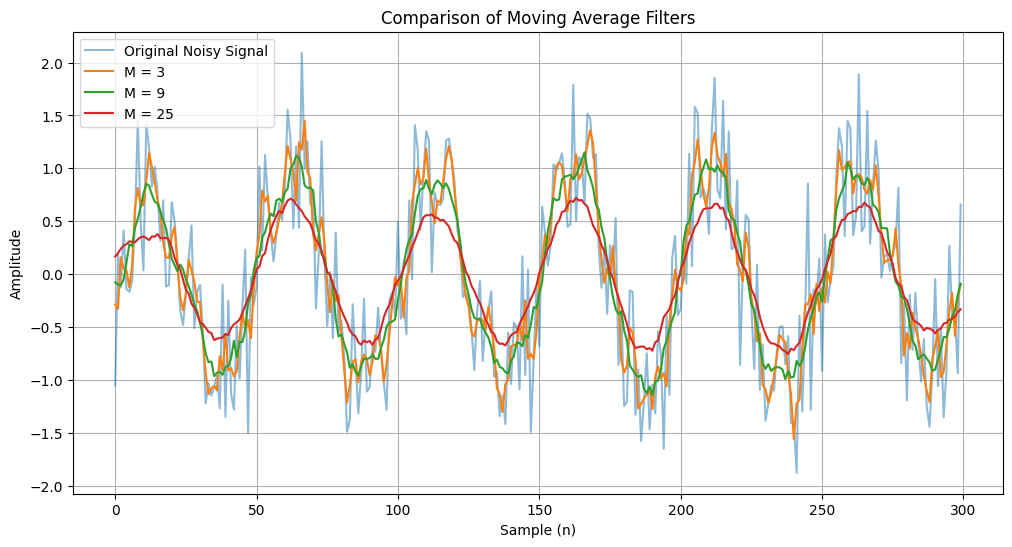

In [17]:
plt.figure(figsize=(12, 6))

plt.plot(n, x, label="Original Noisy Signal", alpha=0.5)
plt.plot(n, y3, label="M = 3")
plt.plot(n, y9, label="M = 9")
plt.plot(n, y25, label="M = 25")

plt.title("Comparison of Moving Average Filters")
plt.xlabel("Sample (n)")
plt.ylabel("Amplitude")

plt.legend()
plt.grid()
plt.show()

**Observation:**

The moving-average filters successfully reduced noise in the original signal. The filter with M = 3 provided slight noise reduction while preserving the signal shape. M = 9 produced better smoothing, while M = 25 provided greater noise reduction but also caused more distortion of the original signal.

**Conclusion:**

Increasing the moving-average filter length improves noise reduction but increases signal distortion. Therefore, a suitable filter length should balance noise reduction and preservation of the original signal.

Task 3.3 — Testing linearity and time-invariance numerically

In [18]:
rng = np.random.default_rng(0)

x1, x2 = rng.standard_normal(50), rng.standard_normal(50)

a, b = 2.0, -3.0

In [19]:
systems = {
    "x^2": lambda x: x**2,

    "n x(n)": lambda x: np.arange(len(x)) * x,

    "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]
}

In [20]:
for name, T in systems.items():

    linear = np.allclose(
        T(a*x1 + b*x2),
        a*T(x1) + b*T(x2)
    )

    xd = np.concatenate([np.zeros(5), x1])[:50]

    yd = np.concatenate([np.zeros(5), T(x1)])[:50]

    tinv = np.allclose(T(xd), yd)

    print(f"{name:15s} linear={linear} time-invariant={tinv}")

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


**Observation:**

The numerical tests showed that the system \(x^2\) is nonlinear but time-invariant. The system \(nx(n)\) is linear but time-varying. The moving-average system is both linear and time-invariant.

**Conclusion:**

A linear system must satisfy the superposition principle, while a time-invariant system must produce an equally delayed output when its input is delayed. The moving-average system satisfies both properties and is therefore an LTI system.

Task 3.4 — Finding a hidden delay with cross-correlation

In [21]:
rng = np.random.default_rng(1)

fs = 1000

x = rng.standard_normal(500)

true_delay = 37

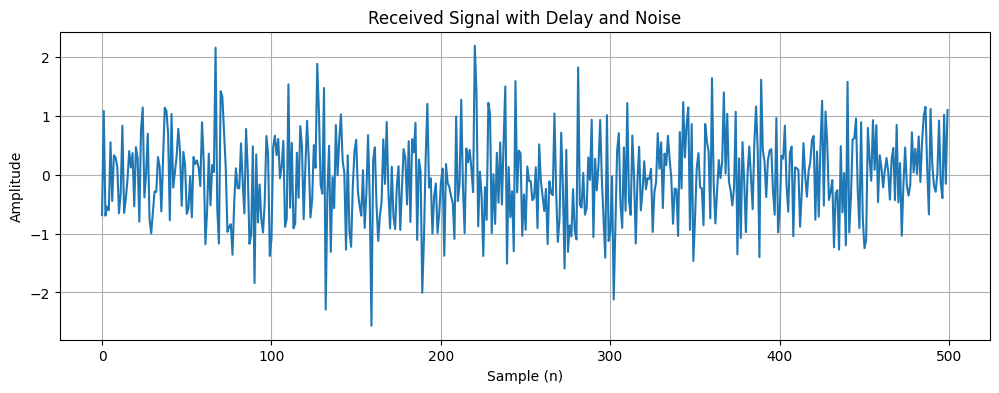

In [22]:
y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + 0.5*rng.standard_normal(500)

plt.figure(figsize=(12, 4))
plt.plot(y)
plt.title("Received Signal with Delay and Noise")
plt.xlabel("Sample (n)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

In [23]:
from scipy import signal

r = signal.correlate(y, x, mode="full")

lags = signal.correlation_lags(len(y), len(x), mode="full")

estimated_delay = lags[np.argmax(r)]

print("Estimated delay:", estimated_delay, "samples")

Estimated delay: 37 samples


In [24]:
delay_seconds = estimated_delay / fs

distance = 343 * delay_seconds

print("Delay time:", delay_seconds, "seconds")
print("Distance:", distance, "meters")

Delay time: 0.037 seconds
Distance: 12.690999999999999 meters


In [25]:
noise = rng.standard_normal(500)

for noise_std in [1, 2, 4]:
    y_test = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + noise_std*noise

    r_test = signal.correlate(y_test, x, mode="full")
    lags_test = signal.correlation_lags(len(y_test), len(x), mode="full")

    estimated = lags_test[np.argmax(r_test)]

    print("Noise standard deviation:", noise_std)
    print("Estimated delay:", estimated, "samples")
    print("----------------------")

Noise standard deviation: 1
Estimated delay: 37 samples
----------------------
Noise standard deviation: 2
Estimated delay: 37 samples
----------------------
Noise standard deviation: 4
Estimated delay: 37 samples
----------------------


Observation

Cross-correlation successfully estimated the delay of 37 samples at noise standard deviations of 1, 2 and 4. Increasing noise did not affect the estimate in this experiment. Therefore, the method remained reliable under the tested noise conditions.

Task 3.5: Solving Difference Equations

In [26]:
n = np.arange(20)

x = np.zeros(20)
x[0] = 1

y = np.zeros(20)

print("Input signal:", x)

Input signal: [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [27]:
for i in range(len(x)):
    x_previous = x[i-1] if i >= 1 else 0
    y_previous = y[i-1] if i >= 1 else 0
    y_previous2 = y[i-2] if i >= 2 else 0

    y[i] = x[i] + x_previous + 0.75*y_previous - 0.125*y_previous2

print("Impulse response using iteration:")
print(y)

Impulse response using iteration:
[1.00000000e+00 1.75000000e+00 1.18750000e+00 6.71875000e-01
 3.55468750e-01 1.82617188e-01 9.25292969e-02 4.65698242e-02
 2.33612061e-02 1.16996765e-02 5.85460663e-03 2.92849541e-03
 1.46454573e-03 7.32347369e-04 3.66192311e-04 1.83100812e-04
 9.15515702e-05 4.57760761e-05 2.28881108e-05 1.14440736e-05]


In [28]:
from scipy.signal import lfilter

b = [1, 1]
a = [1, -0.75, 0.125]

y_filter = lfilter(b, a, x)

print("Impulse response using lfilter:")
print(y_filter)

print("Do both methods match?", np.allclose(y, y_filter))

Impulse response using lfilter:
[1.00000000e+00 1.75000000e+00 1.18750000e+00 6.71875000e-01
 3.55468750e-01 1.82617188e-01 9.25292969e-02 4.65698242e-02
 2.33612061e-02 1.16996765e-02 5.85460663e-03 2.92849541e-03
 1.46454573e-03 7.32347369e-04 3.66192311e-04 1.83100812e-04
 9.15515702e-05 4.57760761e-05 2.28881108e-05 1.14440736e-05]
Do both methods match? True


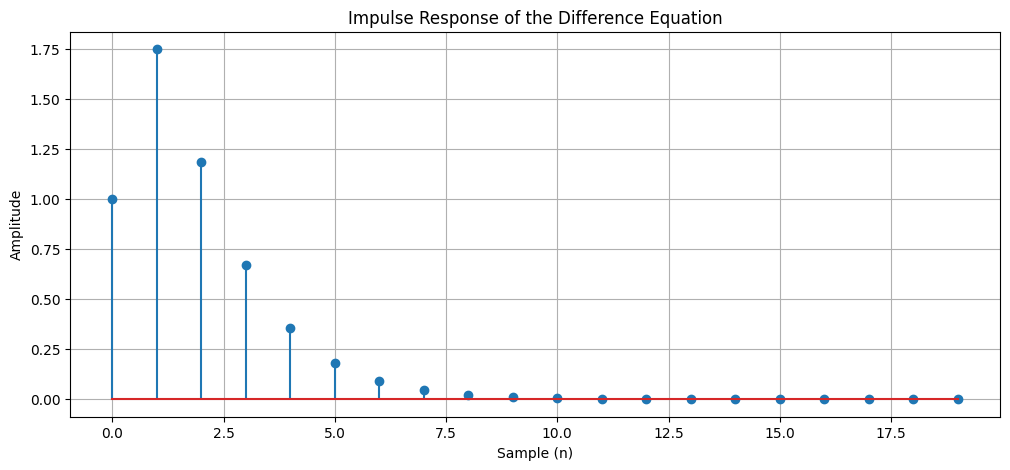

In [29]:
plt.figure(figsize=(12, 5))

plt.stem(n, y)

plt.title("Impulse Response of the Difference Equation")
plt.xlabel("Sample (n)")
plt.ylabel("Amplitude")
plt.grid()

plt.show()

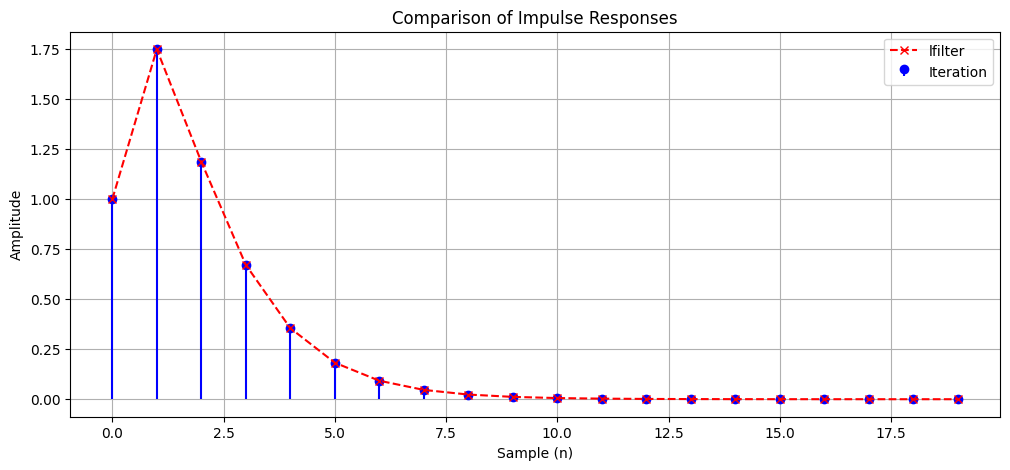

In [30]:
plt.figure(figsize=(12, 5))

plt.stem(n, y, linefmt='b-', markerfmt='bo', basefmt=' ', label="Iteration")

plt.plot(n, y_filter, 'r--', marker='x', label="lfilter")

plt.title("Comparison of Impulse Responses")
plt.xlabel("Sample (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()

plt.show()

Analysis Question 1
Why is np.convolve so much faster than your double loop? What is the number of multiplications for lengths L and M?




`np.convolve` is much faster because it is implemented using highly optimized low-level code, whereas our manually implemented convolution uses Python nested loops, which have more execution overhead.

For two signals of lengths L and M, the number of multiplications required for direct linear convolution is:

\[
\boxed{L \times M}
\]

Therefore, the computational complexity is \(O(LM)\).

For example, if both signals have 2,000 samples, the number of multiplications is:

\[
2000 \times 2000 = 4,000,000
\]



Analysis Question 2
Which of the three systems in Task 3.3 are LTI? Could you have predicted this without running code?

A Linear Time-Invariant (LTI) system must satisfy both linearity and time-invariance.

From Task 3.3:

(x^2): Nonlinear but time-invariant. It is not LTI because it fails the linearity condition.

(n x(n)): Linear but time-varying. It is not LTI because its output depends on the sample index (n).

Moving average: Linear and time-invariant. It satisfies both conditions and is therefore an LTI system.

Yes, these properties could have been predicted without running the code by applying the mathematical definitions of linearity and time-invariance to each system.

Analysis Question 3
Give two engineering applications of cross-correlation in Tanzania.

Water pipe leak detection: Water utilities can use sensors placed along water pipelines to detect sound or vibration signals caused by leaks. Cross-correlation helps estimate the time difference between signals received by different sensors, which can help locate the leak.

Airport radar systems: Airports such as Julius Nyerere International Airport can use radar signal processing to detect aircraft and estimate their distance and movement. Cross-correlation helps compare transmitted and received signals to estimate time delays.

Analysis Question 4
Is the system in Task 3.5 FIR or IIR? Is it stable? Justify from the impulse response?

The system in Task 3.5 is an Infinite Impulse Response (IIR) system because it uses feedback from previous output samples to calculate the current output.

The system is stable because its impulse response gradually decreases towards zero as the sample number increases. This indicates that the impulse response is absolutely summable.

Therefore, the system is a stable IIR system.

In [31]:
h_analytical = 6*(0.5**n) - 5*(0.25**n)

print("Analytical impulse response:")
print(h_analytical)

print("Iteration matches analytical:", np.allclose(y, h_analytical))
print("lfilter matches analytical:", np.allclose(y_filter, h_analytical))

Analytical impulse response:
[1.00000000e+00 1.75000000e+00 1.18750000e+00 6.71875000e-01
 3.55468750e-01 1.82617188e-01 9.25292969e-02 4.65698242e-02
 2.33612061e-02 1.16996765e-02 5.85460663e-03 2.92849541e-03
 1.46454573e-03 7.32347369e-04 3.66192311e-04 1.83100812e-04
 9.15515702e-05 4.57760761e-05 2.28881108e-05 1.14440736e-05]
Iteration matches analytical: True
lfilter matches analytical: True


**AI USE STATEMENT**

Artificial Intelligence (ChatGPT) was used as a learning assistant to help understand Digital Signal Processing concepts, explain Python code, troubleshoot errors and interpret experimental results. All code was executed and tested in Google Colab, and the results were reviewed by the student.